# Намалување на димензијата на податочното множество
Извршете ја следната команда во вашата anaconda околина
* conda install plotly

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import pandas as pd
import seaborn as sns
from scipy import spatial
from sklearn.decomposition import PCA

import plotly.io as pio
pio.renderers.default = 'iframe'

# Концепт на намалување на димензија на проблемот
Од предходните вежби е познато дека две карактеристики се редундантни доколку корелацијата помеѓу нив е -1 или 1. Според тоа, една од нив отстранувавме со цел да го забрзаме тренирањето на моделот. Во некои случаеви, корелацијата помеѓу две карактеристики може да не е 1 или -1 но истата да е блиска до овие вредности. Во ваква ситуација тоа ни кажува дека двете карактеристики се многу слични. Се поставува прашањето дали овие две карактеристики можеме да ги сведеме на само една карактеристика, која ќе ја содржи информацијата од обете. Дополнително постои можноста определена карактеристика да не придонесува кон решавање на проблемот и истата да е непотребна. Пристапот на намалување на бројот на карактеристики во вакви случаеви нарекува намалување на димензијата на проблемот (dimensionality reduction).


**Дефиниција на корелација и коваријанса**

Од предходните вежби беше покажано дека корелацијата помеѓу две карактеристики  претставува мерна вредност во опсегот [-1, 1] за тоа колку тие две карактеристики се зависни една од друга. Вредноста 1 претставува идеално растечка линеарна зависност од типот $x_2 = ax_1, а > 0$, a вредноста -1 претставува идеално опаѓачка линеарна зависност од типот $x_2 = -ax_1, a>0$. Вредност 0 ни кажува дека воопшто не постои растечка или опаѓачка зависност помеѓу карактеристиките.

Корелацијата помеѓу две карактеристики се пресметува како:

$$Corr(x_1, x_2) = \frac{\Sigma^n_{i=1}(x_{1i} - \bar x_1)(x_{2i} - \bar x_2)}{\sqrt{\Sigma^n_{i=1}(x_{1i} - \bar x_1)^2\Sigma^n_{i=1}(x_{2i} - \bar x_2)^2}}$$

Тука ќе биде воведена уште една статистичка мерка која се нарекува коваријанса. Корелацијата всушност претставува скалирана верзија на коваријансата. Имено, коваријансата дава вредности во опсег $(-\infty, \infty)$ за тоа колку две променливи се растечко или опаѓачко зависни една од друга. Коваријансата се пресметува како:

$$Covri(x_1, x_2) = \frac{\Sigma^n_{i=1}(x_{1i} - \bar x_1)(x_{2i} - \bar x_2)}{n}$$

Коваријансата може да има повисоки вредности кога променливите $x_1$ и $x_2$ имаат повисоки вредности, иако зависноста е иста. За да се избегне овој проблем всушност коваријансата се скалира и се добива тоа што го нарекуваме корелација.

**Проблем на предвидување на цена на куќа со две слични карактеристики**

Во овој случај ќе дефинираме проблем на предвидување на цена на куќа каде што карактеристиките не се линеарно зависни, но меѓусебно се многу слични. Се поставува прашањето дали сличноста помеѓу двете карактеристики ќе можеме да ја воочиме доколку проблемот го претставиме на график со оски: цена на куќа, карактеристика 1, карактеристика 2.

1. Ќе дефинираме две карактеристики со 1000 вредности каде што ќе постои зависност помеѓу нив која е блиска до 1
2. Нека овие две карактеристики претставуваат плоштината на куќите претставена во $m^2$ и $ft^2 + шум$
3. Шумот го дефинираме според гаусова распределба со средна вредност 0 и стандардна девијација 50

In [32]:
xm = np.random.normal(60, 30, 1000) # плоштина на куќа во m^2
xf = 10.76*xm + np.random.normal(0, 50, 1000) # плоштина на куќа во ft^2 + шум 

### Двете карактеристики претставени на график зависни една од друга

Text(0, 0.5, 'Плоштина на куќа во ft^2 + шум')

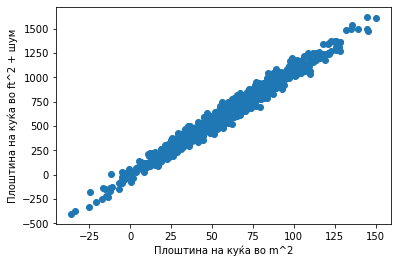

In [33]:
plt.scatter(xm, xf)
plt.xlabel('Плоштина на куќа во m^2')
plt.ylabel('Плоштина на куќа во ft^2 + шум')

Од графикот може да се забележи дека карактеристиките навистина се растечко зависни една од друга, но не идеално.

### Ќе ја дефинираме зависноста на цената на куќа преку овие карактеристики
Ќе сметаме дека $1m^2$ чини 1000 долари и еквивалентно истото важи за $1ft^2$ каде $1ft^2 =  0.09290304m^2$.

In [34]:
y = 1000*xm + 1000*0.09290304*xf # цена на куќа во евра

### Визуелизација на проблемот во 3Д

In [35]:
fig = px.scatter_3d(x=xm, y=xf, z=y, labels={'x': 'Плоштина на куќа во m^2', 'y': 'Плоштина на куќа во ft^2 + шум', 'z': 'Цена на куќа'})
fig.update_layout(
    autosize=False,
    width=1000,
    height=1000,
    title_text='Цена на куќи според плоштина'
)
fig.show()

Забележете од графикот дека, покрај тоа што имаме две карактеристики, доволно би била само една линија за предвидување на проблемот наместо да се користи рамнина во 3Д просторот. Фактот дека е доволно линија за предвидување ни кажува дека би можеле димензијата на проблемот да ја сведеме на само една карактеристика.

### Концепт корелациона матрица
Корелациона матрица помеѓу две карактеристики (x1, x2) ни ги дава корелациите за сите комбинации од карактеристики (x1, x1), (x1, x2), (x2, x1), (x2, x2). За проблемот од погоре корелационата матрица ќе биде:

In [36]:
print("Корелациона матрица на проблемот:\n", np.corrcoef(xm, xf))

Корелациона матрица на проблемот:
 [[1.        0.9885159]
 [0.9885159 1.       ]]


Корелационна матрица за n карактеристики ги дава корелациите за сите парови на комбинации од тие n карактеристики.

## Концепт на Principal Component Analysis (PCA)

Еден од начините за да се намали димензијата на проблемот, а притоа да се задржи дел од информацијата од карактеристиките кои се елиминираат, е преку примена на PCA. Едноставно објаснување за тоа како функционира PCA е следното. Може да се смета дека целта на PCA  е да генерира ист број на нови карактеристики, кај кои информацијата од старите карактеристики е еквивалентно распределена. Потоа кај овие ново генерирани карактеристики се елиминира онаа која најмалку придонесува кон варијансата на податочното множество.

Оваа постапка се реализира преку следните чекори:
1. Наоѓање на коваријансна матрица на проблемот
2. Наоѓање на сопствени вектори на коваријансната матрица
3. Елиминација на оние сопствени вектори со најмал интензитет (најмала варијанса)
4. Останатите сопствени вектори ги претставуваат новите карактеристики
5. За да се добие трансформираното податочно множество, се проектираат податочните точки врз останатите сопствени вектори

### Концепт на коваријансна матрица
Коваријансната матрица е многу слична на корелационата матрица. Наместо корелациите, таа ги дава коваријансите помеѓу сите комбинации од парови за дадените карактеристики. Коваријанса за (x1, x1) ја дава варијансата на x1. Според тоа по главната дијагонала на матрицата ќе бидат сместени варијансите на самите карактеристики.

### Пример 1 (растечки линеарно зависни карактеристики) за пресметка на коваријансна матрица
Се дефинираат две карактеристики:

x1 = [1, 2, 3]

x2 = [2, 4, 6]

In [37]:
x1 = np.array([1, 2, 3])
x2 = np.array([2, 4, 6])

Text(0, 0.5, 'карактеристика 2')

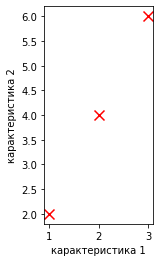

In [38]:
plt.scatter(x1, x2, c='r', marker='x', s= 100)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlabel('карактеристика 1')
plt.ylabel('карактеристика 2')

Од графикот може да се забележи дека имаме идеална растечка линеарна зависност помеѓу двете карактеристки. Според тоа коваријансната матрица ќе биде:

In [39]:
print("Коваријансна матрица:\n", np.cov([x1, x2], ddof=0))

Коваријансна матрица:
 [[0.66666667 1.33333333]
 [1.33333333 2.66666667]]


### Пример 2 (опаѓачко линеарно зависни карактеристики) за пресметка на коваријансна матрица
Се дефинираат две карактеристики:

x1 = [1, 2, 3]

x2 = [-2, -4, -6]

In [40]:
x1 = np.array([1, 2, 3])
x2 = np.array([-2, -4, -6])

Text(0, 0.5, 'карактеристика 2')

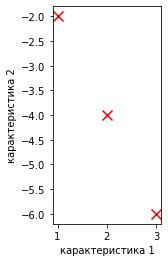

In [41]:
plt.scatter(x1, x2, c='r', marker='x', s= 100)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlabel('карактеристика 1')
plt.ylabel('карактеристика 2')

Од графикот може да се забележи дека имаме идеална опаѓачка линеарна зависност помеѓу двете карактеристки. Според тоа коваријансната матрица ќе биде:

In [42]:
print("Коваријансна матрица:\n", np.cov([x1, x2], ddof=0))

Коваријансна матрица:
 [[ 0.66666667 -1.33333333]
 [-1.33333333  2.66666667]]


### Пример 3 (нема зависност помеѓу карактеристиките) за пресметка на коваријансна матрица
Се дефинираат две карактеристики:

x1 = [1, 2, 3]

x2 = [3, 2, 3]

In [43]:
x1 = np.array([1, 2, 3])
x2 = np.array([3, 2, 3])

Text(0, 0.5, 'карактеристика 2')

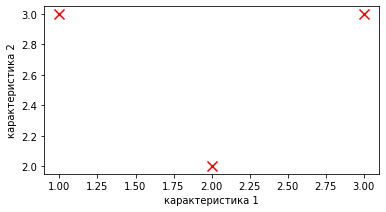

In [44]:
plt.scatter(x1, x2, c='r', marker='x', s= 100)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlabel('карактеристика 1')
plt.ylabel('карактеристика 2')

Од графикот може да се забележи имаме и пад и раст кај карактеристика 2 во зависност од карактеристика 1. Според тоа коваријансната матрица ќе биде:

In [45]:
print("Коваријансна матрица:\n", np.cov(np.vstack((x1, x2)), ddof=0))

Коваријансна матрица:
 [[0.66666667 0.        ]
 [0.         0.22222222]]


### Сопствени вектори на коваријансна матрица
Сопствените вектори на коваријансната матрица секогаш се насочени во правец на максималната варијанса на податочното множество. Со нивна помош може да се извлече во кој правец најмногу може да се извлече информацијата од податочното множество.

In [46]:
u, sigma, v = np.linalg.svd(np.cov([1, 2, 3], [2, 4, 6], ddof=0))

#### Пример 1 (растечки линеарно зависни карактеристики) визуелизација на сопствени вектори
Се дефинираат две карактеристики:

x1 = [1, 2, 3]

x2 = [2, 4, 6]

Text(0, 0.5, 'карактеристика 2')

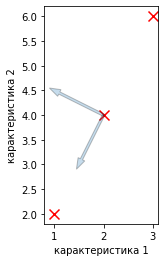

In [47]:
plt.arrow(0 + 2, 0 + 4, u[0, 0], u[1, 0], width=0.05, alpha=0.25)
plt.arrow(0 + 2, 0 + 4, u[0, 1], u[1, 1], width=0.05, alpha=0.25)
plt.scatter([1, 2, 3], [2, 4, 6], c='r', marker='x', s= 100)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlabel('карактеристика 1')
plt.ylabel('карактеристика 2')

Векторите се позиционирани во правец каде што е најголема варијансата на податочното множество.

#### Пример 2 (опаѓачко линеарно зависни карактеристики) визуелизација на сопствени вектори
Се дефинираат две карактеристики:

x1 = [1, 2, 3]

x2 = [-2, -4, -6]

In [48]:
u, sigma, v = np.linalg.svd(np.cov([1, 2, 3], [-2, -4, -6], ddof=0))

Text(0, 0.5, 'карактеристика 2')

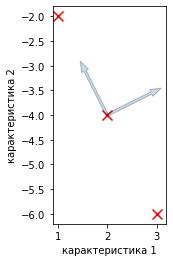

In [49]:
plt.arrow(0 + 2, 0 - 4, u[0, 0], u[0, 1], width=0.05, alpha=0.25)
plt.arrow(0 + 2, 0 - 4, u[1, 0], u[1, 1], width=0.05, alpha=0.25)
plt.scatter([1, 2, 3], [-2, -4, -6], c='r', marker='x', s= 100)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlabel('карактеристика 1')
plt.ylabel('карактеристика 2')

Векторите се позиционирани во правец каде што е најголема варијансата на податочното множество.

### Пример 3 (нема зависност помеѓу карактеристиките) визуелизација на сопствени вектори
Се дефинираат две карактеристики:

x1 = [1, 2, 3]

x2 = [3, 2, 3]

In [50]:
u, sigma, v = np.linalg.svd(np.cov([1, 2, 3], [3, 2, 3], ddof=0))

Text(0, 0.5, 'карактеристика 2')

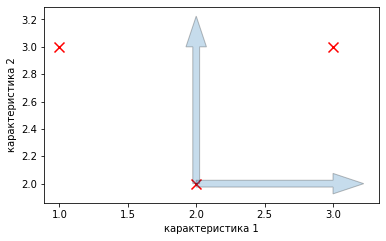

In [51]:
plt.arrow(0 + 2, 0 + 2, u[0, 0], u[0, 1], width=0.05, alpha=0.25)
plt.arrow(0 + 2, 0 + 2, u[1, 0], u[1, 1], width=0.05, alpha=0.25)
plt.scatter([1, 2, 3], [3, 2, 3], c='r', marker='x', s= 100)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlabel('карактеристика 1')
plt.ylabel('карактеристика 2')

Кога не постои зависност помеѓу карактеристиките тогаш сопствените вектори се колинеарни со векторите на карактеристиките.

### Наоѓање на сопствени вектори за примерот од погоре (цена на куќа)

In [52]:
dataset = np.vstack((xm, xf))

In [53]:
e, u = np.linalg.eig(np.cov(dataset, ddof=0))
scale = 1/100

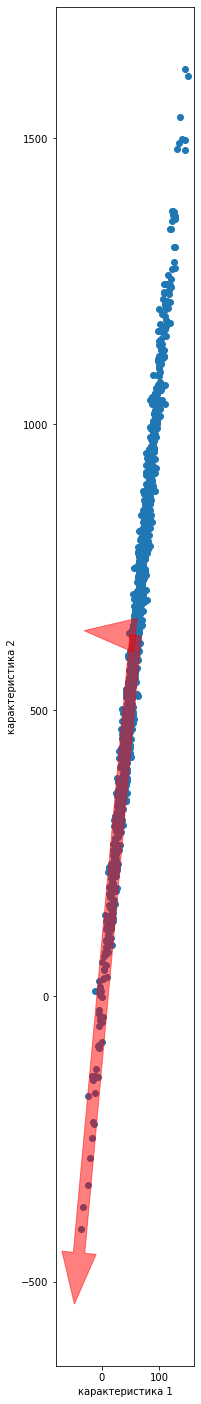

In [54]:
plt.figure(figsize=(25, 25))
plt.arrow(xm.mean(), xf.mean(), e[0]*scale*u[0, 0], e[0]*scale*u[1, 0], width=20, alpha=0.5, color='r')
plt.arrow(xm.mean(), xf.mean(), e[1]*scale*u[0, 1], e[1]*scale*u[1, 1], width=20, alpha=0.5, color='r')
plt.scatter(xm, xf)
plt.xlabel('карактеристика 1')
plt.ylabel('карактеристика 2')
plt.gca().set_aspect('equal', adjustable='box')

Може да се забележи дека векторите се позиционирани во правец каде е најголема варијансата на податочното множество. За да го намалиме бројот на димензии на проблемот, ќе го елиминираме оној вектор, во чиј правец, податочното множество има помала варијанса. Во овој случај тоа е векторот кој покажува кон 21:30 часот.. 

Според тоа векторот кој покажува 19:00 часот ќе го земеме како една карактеристика и точките од податочното множество ќе ги проектираме врз него.

Text(0.5, 0, 'Имплицитна карактеристика добиена од старите')

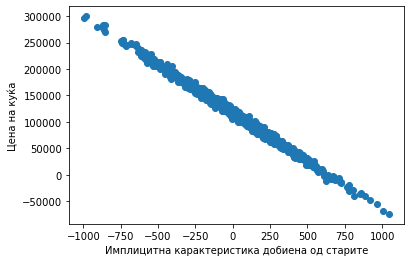

In [55]:
X = dataset.T
pca = PCA(n_components=1) # примена на PCA според фиксиран број на карактеристики
X = pca.fit_transform(X)

plt.scatter(X, y)
plt.ylabel('Цена на куќа')
plt.xlabel('Имплицитна карактеристика добиена од старите')

Во овој случај имаме само една карактеристика. Новата карактеристика нема физичко значење и не може да се определи мерна единица за неа како што беше определено за старите карактеристики ($m^2$, $ft^2$).

# Зошто имаме потреба од намалување на димензиите на проблемот?

Најчесто се смета дека поголем број на карактеристики носат повеќе информација при тренирање на моделот, а тоа би довело и до попрецизен модел. Сепак, треба да се внимава овој број на карактеристики да не стане преголем поради проблемот на Dimensionality Curse. Имено, доколку бројот на редици во податочното множество остане ист, а бројот на колони се зголемува, може да настанат низа проблеми. Постојат повеќе недостатоци коишто можат да произлезат како резултат на премногу карактеристики:

1. **Проретчување на податочното множество:** Колку повеќе карактеристики се додаваат толку повеќе се зголемува просторот во кој се простираат податочните точки. Како резултат на тоа податочното множество се проретчува и поголем дел од просторот во кој се простира податочното множество е празен. Ова го отежнува моделите за класификација и кластерирање.

2. **Побарување на компјутациона моќ:** Поголеми податочни множества побаруваат повеќе хардверски ресурси и време за тренирање.

3. **Overfitting:** Поголем број на карактеристики може да придонесат кон зголемување на шумот во податочното множество. Присуството на шумот може да ја деградира способноста на моделот да наоѓа зависности помеѓу влезната и излезната променлива. Кога се зголемува бројот на карактеристики, а бројот на податоци останува ист, податочното множество се проретчува и се' повеќе се зголемува бројот на комбинации од вредности за секоја карактеристика коишто алгоритмот не ги видел при тренирање. Според тоа, просторот во кој може да се најдат новите точки за предвидување е поголем и поверојатно е дека моделот никогаш не ги видел истите во минатото при тренирање.

4. **Се губи значењето на растојание помеѓу податочните точки:** Со зголемување на просторот во кој се простира податочното множество, истовремено се зголемува и растојание помеѓу податочните точки. Колку овие точки се оддалечуваат меѓусебно толку варијабилноста на растојанието помеѓу нив станува излишна. Имено, колку повеќе се зголемува бројот на карактеристики, толку ова растојание, помеѓу секој пар од точки, тежнее кон иста идентична вредност. Според тоа, модели базирани на растојание како: KNN, KMeans, DBSCAN нема да можат да предвидуваат во ваков случај.

### Симулација за губење на значењето на растојание помеѓу податочните точки
Во овој пример ќе дефинираме податочно множество чиј број на карактеристики ќе го зголемуваме според:
dimensions = [20, 50, 100, 500, 1000, 10000, 20000, 50000]

Со зголемување на бројот на карактеристики ќе го мериме растојанието помеѓу секоја од точките, во податочното множество, и ќе ги пресметуваме следните метрики:
* просечно растојание за целото податочно множество
* минимално растојание
* сооднос од минималното растојание и просечното растојание

**Внимание: времето на извршување на оваа ќелија е подолго од вообичаено**

In [56]:
dimensions = [20, 50, 100, 500, 1000, 10000, 20000, 50000]
avg = []
mmin = []
ratio = []
for nr, dimension in enumerate(dimensions):
    X = np.empty((200, 0))
    for i in range(1, (dimension + 1)//2):
        x1_c1 = np.random.normal(0, 1, 100)
        x2_c1 = np.random.normal(0, 1, 100)

        x1_c2 = np.random.normal(0, 1, 100)
        x2_c2 = np.random.normal(0, 1, 100)
        X = np.hstack((X, np.vstack((np.append(x1_c1, x1_c2), np.append(x2_c1, x2_c2))).T))
    pom = spatial.distance.cdist(X, X).flatten()
    avg.append(pom.mean())
    mmin.append(pom[pom != 0].min())
    ratio.append(mmin[len(mmin) - 1]/avg[len(avg) - 1])

### Илустрација на трендот на просечното растојание наспрема бројот на карактеристики

Text(0, 0.5, 'Просечно растојание од сите парови од точки')

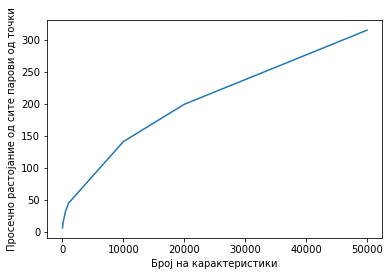

In [57]:
plt.plot(dimensions, avg)
plt.xlabel('Број на карактеристики')
plt.ylabel('Просечно растојание од сите парови од точки')

### Илустрација на трендот на минималното растојание наспрема бројот на карактеристики

Text(0, 0.5, 'Минимално растојание од сите парови од точки')

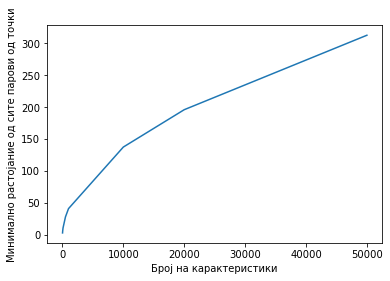

In [58]:
plt.plot(dimensions, mmin)
plt.xlabel('Број на карактеристики')
plt.ylabel('Минимално растојание од сите парови од точки')

### Илустрација на трендот на сооднос минимално растојание / просечно растојание

Text(0, 0.5, 'Сооднос на минимално/Просечно растојание од сите парови од точки')

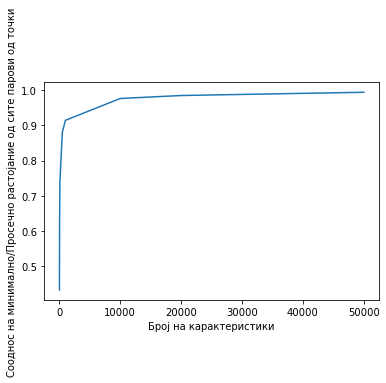

In [59]:
plt.plot(dimensions, ratio)
plt.xlabel('Број на карактеристики')
plt.ylabel('Сооднос на минимално/Просечно растојание од сите парови од точки')

**Соодносот на минималното и просечното растојание тежнее кон 1 со зголемување на бројот на карактеристики. Тоа значи дека точките тежнеат да се оддаелечуваат кога бројот на карактеристики се зголемува, а дополнитело растојанието помеѓу секој пар од точки тежнее да стане исто.**

### Симулација за проблем на overfitting  

Да претпоставиме дека имаме проблем на класификација чии карактеристики можат да имаат вредности од множеството {0, 1}.

Во овој случај ќе претпоставиме дека за секоја комбинација од вредности за карактеристиките ќе ни требаат минимум 10 податочни точки за да можеме да го истренираме моделот да предвидува задоволително. 

Според тоа, трендот на потребниот број на податоци според бројот на карактеристики ќе биде следниот:

1. Една карактеристика -> две комбинации од вредности {0, 1} -> 2*10 = 20 потребни податочни точки
2. Две карактеристики -> четири комбинации од вредности {00, 01, 10, 11} -> 4*10 = 40 потребни податочни точки

    .

    .

    .

3. n Карактеристики -> $2^n$ комбинации од вредности -> $2^n*10$ потребни податочни точки

**Според овам бројот на потребни податоци за тренирање се зголемува експоненцијално со зголемување на бројот на карактеристики**

#### Илустрација на трендот за потребни редици во податочното множество, со зголемувањето на бројот на колони
Колоните можат да имаат вредност само 0 или 1.

Text(0, 0.5, 'Потребен број на податоци за тренирање')

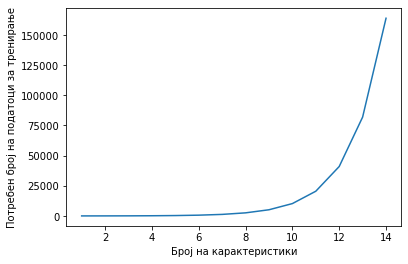

In [60]:
feature_number = np.arange(1, 15, 1)
plt.plot(feature_number, np.power(2*np.ones(feature_number.shape), feature_number)*10)
plt.xlabel('Број на карактеристики')
plt.ylabel('Потребен број на податоци за тренирање')

Според тоа, со зголемување на бројот на карактеристики се јавува потреба од повеќе податоци. Доколку оваа потреба не се задоволи, се ризикува моделот да потфрли поради overfitting. Овој проблем најчесто се појавува кај покомплексни модели.

## Практични забелешки при примена на PCA
* При примена на PCA битно е да се применува алгоритмот соодветно на множеството за тренирање и множествоото за тестирање/валидација

* Правилото за примена е исто како и кај нормализација на податоците. Fit се применува на множеството за тренирање, а transform се применува на множеството за тестирање/валидација

* Доколку се примени fit  на множеството за тестирање/валидација се ризикува да се направи overfitting поради проток на информација од множеството за тестирање/валидација во множеството за тренирање.

* При примена на PCA() класата од sklearn постојат два начина за намалување на димензијата на податочното множество преку параметарот **n_components** . Ако вредноста која се внесува за **n_components** е целобројна, тогаш се внесува посакуваниот број на колони кои сака корисникот да ги задржи во податочното множество. Ако вредноста која се внесува е во опсегот (0, 1), тогаш се внесува посакуваниот процент на варијанса кој сака корисникот да го задржи во податочното множество. Во овој случај се елиминираат толку колони така што варијансата на множеството не е помала од **n_components**.

# Предвидување на титаник податочно множество со помош на SVM

Податоците за преживеаните патници од бродот Titanic ќе ги искористиме за да изградиме модел кој ќе предвидува кој има поголема веројатност да преживее.

Податочното множество ги содржи следните колони:

* **PassengerId:** Идентификациски број на патникот
* **Pclass:** Патничка класа
* **Name:** Име на патникот
* **Sex:** Пол на патникот
* **Age:** Возраст на патникот
* **SibSp:** Број на браќа-сестри/брачен другар кои што се со патникот на бродот
* **Parch:** Број на родители/деца кои што се со патникот на бродот
* **Ticket:** Број на билетот
* **fare:** Цена на билетот
* **Cabin:** Број на кабина во која бил сместен патникот
* **Embarked:** Пристаниште каде се качил патникот
* **Survival:** Дали преживеал патникот

Дополнителни информации за некои од колоните кои вие треба да ги увидите преку истражување на податоците:

    Pclass:
        1st = Прва класа
        2nd = Средна класа
        3rd = Ниска класа
        
    sibsp: Роднинските врска можат да бидат претставени на следниот начин...
        Sibling = брат, сестра, полубрат, полусестра
        Spouse = Сопруг, сопруга (верениците се игнорирани)

    parch: Роднинските врска можат да бидат претставени на следниот начин
        Parent = мајка, татко
        Child = ќерка, син, полусин, полуќерка
        Некои деца патувале само со дадилка, последователно parch=0 за нив.

## Користени библиотеки

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

### Вчитување на податочното множество (titanic_train.csv)
Прочитајте го податочното множество и сместете го во табела со име data.

* Изоставете ја колоната за PassengerId
* Прочитајте го колоните со соодветните податочни типови за да заштедите на меморија

**помош: pandas.read_csv()**

In [3]:
data = pd.read_csv('titanic_train.csv', 
                   dtype={'Pclass': 'uint8', 'Age': 'float16', 'SibSp': 'uint8', 'Parch': 'uint8', 'Survived': 'bool'}, 
                   usecols=range(1, 12))

### Испечатете општи информации за податочното множество

**помош: pandas.*.info()**

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    bool   
 1   Pclass    891 non-null    uint8  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float16
 5   SibSp     891 non-null    uint8  
 6   Parch     891 non-null    uint8  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: bool(1), float16(1), float64(1), object(5), uint8(3)
memory usage: 47.1+ KB


### Отстранете ги непотребнити колони од табелата
* Ticket

**помош: pandas.drop()**

In [5]:
data.drop(columns=['Ticket'], inplace=True)

### Ослободете се од NaN вредностите во податочното множество

Разрешети ги NaN вредностите од колоната за возраст така што ќе замените со средна вредност според пол и патничка класа.

* Најпрво пресметајте средна возраст според пол и патничка класа за секоја комбинација: (male, Pclass1), (male, Pclass2), (male, Pclass3), (female, Pclass1), (female, Pclass2), (female, Pclass3).
* Потоа искористете ги овие средни возрасти за да ги пополните NaA вредностите според полот и патничката класа на патникот

**помош: pandas.*.drop(), pandas.*.dropna(), pandas.*.groupby()**

In [6]:
data.dropna(axis=0, subset=['Embarked'],  inplace=True)

data.drop(columns='Cabin', inplace=True)


means = data.groupby(['Sex', 'Pclass'])['Age'].mean() 
for sex, pclass in means.index:
    data.loc[data['Age'].isnull() & (data['Sex'] == sex) & (data['Pclass'] == pclass), 'Age'] = means[sex][pclass]

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 889 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  889 non-null    bool   
 1   Pclass    889 non-null    uint8  
 2   Name      889 non-null    object 
 3   Sex       889 non-null    object 
 4   Age       889 non-null    float16
 5   SibSp     889 non-null    uint8  
 6   Parch     889 non-null    uint8  
 7   Fare      889 non-null    float64
 8   Embarked  889 non-null    object 
dtypes: bool(1), float16(1), float64(1), object(3), uint8(3)
memory usage: 39.9+ KB


### Разрешете го проблемот со категорички карактеристики

1. SVM не знае да работи со string вредности. Замените ги вредностите во колоната за пол според следниов пример:
    * 'male' -> 0
    * 'female' -> 1

2. Примeнете one-hot-encoding за Embarked колоната

**помош: pandas.concat(), pandas.get_dummies(), pandas.*.drop(), pandas.*.map()**

In [8]:
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})

In [9]:
data = pd.concat([data, 
                  pd.get_dummies(data['Embarked'], prefix='Embarked', drop_first=True)], axis=1)

In [10]:
data.drop(columns='Embarked', inplace=True)

In [11]:
data = pd.concat([data, 
                  pd.get_dummies(data['Pclass'], prefix='Pclass', drop_first=True)], axis=1)

In [12]:
data.drop(columns='Pclass', inplace=True)

In [13]:
data.columns

Index(['Survived', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked_Q', 'Embarked_S', 'Pclass_2', 'Pclass_3'],
      dtype='object')

### Генерирајте нови карактеристики од податочното множество според следниве насоки


1. **Титула на патникот:** Од името на патникот може да биде извлечена титула како Sir, Mr, Miss, Mrs, Master, Lady, Countess, Dr, итн. Од оваа титула може да се процени значајноста на патникот како Lady, Sir, Countess, Captain, Colonell, Master, Dr итн. Овие титули можат да се искористат за поделба на патниците според Најзначајни, значајни и незначајни. Титулите Miss и Mrs дополнително може да се искористат како дополнителна карактеристика.
2. **Дали патникот е дете:** Можеме да ги земеме сите патници под 12 години како деца.
3. **Брачен статус на жена:** Венчаните дами можеме да се проценат според титулата Mrs.
4. **Дали патникот има деца со него:** Дамите постари од 18 години со ненулева вредност за Parch колоната може да се претпостави дека имаа деца.

**помош: pandas.dataframe.str.contains()**

**помош: Информирајте се за regex со цел да можете да ја користите препорачаната функција str.contains()**

In [14]:
data['Noble'] = data['Name'].str.contains('Sir\.|Countess\.|Lady\.', regex=True)

In [15]:
data['MarriedW'] = data['Name'].str.contains('Mrs.')

In [16]:
data['Has_child'] = (data['Sex'] == 1) & (data['Parch'] >= 1) & (data['Age'] > 18)

Со оваа постапка додадовме 3 нови карактеристики добиени од податочното множество.

### Елиминирајте ја Name колоната
SVM моделот не може да работи со string вредности.

**помош: pandas.drop()**

In [17]:
data.drop(columns=['Name'], inplace=True)

### Проверете го вкупниот број на карактеристики до сега

**помош: pandas.*.info()**

In [18]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 889 entries, 0 to 890
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    889 non-null    bool   
 1   Sex         889 non-null    int64  
 2   Age         889 non-null    float16
 3   SibSp       889 non-null    uint8  
 4   Parch       889 non-null    uint8  
 5   Fare        889 non-null    float64
 6   Embarked_Q  889 non-null    uint8  
 7   Embarked_S  889 non-null    uint8  
 8   Pclass_2    889 non-null    uint8  
 9   Pclass_3    889 non-null    uint8  
 10  Noble       889 non-null    bool   
 11  MarriedW    889 non-null    bool   
 12  Has_child   889 non-null    bool   
dtypes: bool(4), float16(1), float64(1), int64(1), uint8(6)
memory usage: 31.3 KB


### Поделете го множество на train и test

**помош: train_test_split(test_size=1/3, random_state=0)**

In [19]:
X = data.drop(columns=['Survived'])
y = data['Survived']

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X.to_numpy(), y.to_numpy(), test_size = 1/3, random_state=0)

### Применете PCA
Вообичеано не е од корист да се применува PCA врз категорички бинарни карактеристики. Применете PCA само на нумеричките карактеристики.

* Извлечете ги нумеричките карактеристики од X_train како една табела
* Применете PCA врз таа табела
* Избришете ги нумеричките карактеристики од X_train и прилепете го излезот од PCA

Клучни параметри за PCA():
* **n_components:** 1 
* **random_state:** 0

**помош:PCA(), numpy.delete(), numpy.unique()**

### Изградете SVM модел за класификација и истренирајте го
Параметри за моделот:

* **kernel:** 'rbf'
* **tol:** 1e-6
* **random_state:** 0
* **C:** 1e3
* **gamma:** 1e-3

**помош: sklearn.SVC(), sklearn.SVC().*.fit()**

### Извршете f1_score евалуација на моделот врз тест множеството

**помош: classification_report(), GridSearchCV.\*.predict(), PCA.\*.transform()**

Испробајте го истиот модел така што за PCA ќе примените n_components=4, односно нема да елиминирате ниту една од карактеристиките. Воочете дека macro avg за F1_score е за 0.01 помало од предходно што значи дека зголемување на бројот на карактеристики за 3 повеќе не придонесе во подобрување на моделот.